# A1-1 이커머스 고객 분석 리포트: 단골 찾기

영국 온라인 선물용품 쇼핑몰의 1년 치 주문 데이터(UCI Online Retail)를 정리하고, RFM으로 고객을 나눠 어떤 고객에게 무엇을 해야 할지 찾는다.

| 단계 | 내용 | 사용하는 `DataAnalyzer` 메서드 |
| --- | --- | --- |
| 1 | 데이터 로드와 구조 파악 | `load_data()` |
| 2 | 결측치 확인과 그룹별 대치 | `summarize_missing()`, `convert_invalid_to_missing()`, `handle_missing_values()` |
| 3 | 텍스트·금액·이미지 피처 생성 | `add_text_features()`, `add_amount()`, `add_image_features()` |
| 4 | 분석 대상 거래 고르기 | `filter_valid_transactions()` |
| 5 | IQR 이상치 탐지·처리 | `detect_outliers()`, `clip_outliers()` |
| 6 | 통계 요약·상관 분석 | `summarize_numeric()`, `calculate_correlations()` |
| 7 | 범주·시계열 분석 | `calculate_monthly_revenue()` |
| 8 | RFM 세분화 | `calculate_rfm()`, `segment_customers()`, `summarize_segments()` |

분석 로직은 `src/pipeline.py`에 있고, 이 노트북은 그 클래스를 불러 결과를 보고 해석한다. 그림은 `outputs/figures/`에 PNG로도 저장된다.

> 이미지 데이터 안내: 원본 거래 데이터에는 상품 이미지가 없다. 상품코드마다 Fashion-MNIST(MIT 라이선스) 이미지 1장을 시드 42로 무작위 연결해 '이미지 → 수치 피처' 과정을 실습한다. 실제 상품 사진이 아니므로 이미지 피처와 매출의 관계는 해석하지 않는다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import font_manager

# 노트북은 notebooks/ 에서 실행되므로 한 단계 위(A1-1)를 프로젝트 루트로 본다.
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from pipeline import DataAnalyzer, load_idx_images  # noqa: E402

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "data.csv"
IMAGE_PATH = PROJECT_ROOT / "data" / "raw" / "t10k-images-idx3-ubyte.gz"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

IQR_MULTIPLIER = 1.5
RANDOM_SEED = 42
MIN_VALID_PRICE = 0.001   # 단가가 이보다 작으면(0 이하) 잘못된 값으로 본다

# 한글 제목이 깨지지 않도록 설치된 한글 글꼴 중 하나를 고른다.
KOREAN_FONTS = ["Malgun Gothic", "AppleGothic", "NanumGothic",
                "Noto Sans CJK KR", "Noto Sans CJK JP"]
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in KOREAN_FONTS:
    if font_name in installed_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False  # 마이너스 기호 깨짐 방지
sns.set_theme(style="whitegrid", font=plt.rcParams["font.family"])
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 120)


def save_figure(fig, file_name):
    """그림을 outputs/figures/ 에 PNG로 저장한다."""
    fig.savefig(FIGURE_DIR / file_name, dpi=120, bbox_inches="tight")

## 1. 데이터 로드와 기본 탐색

`load_data()`는 CSV를 Latin-1 인코딩으로 읽고, 주문일을 날짜형으로, 고객 ID를 문자열로 바꾼다. 상품코드·주문번호·고객 ID는 숫자처럼 보여도 계산할 값이 아니라 '이름'이기 때문이다.

In [2]:
analyzer = DataAnalyzer(DATA_PATH)
raw_df = analyzer.load_data()
raw_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [3]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(4), string(1)
memory usage: 33.1 MB


In [4]:
raw_df.describe()

,Quantity,InvoiceDate,UnitPrice
count,"541,909.00",541909,"541,909.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06"
25%,1.00,2011-03-28 11:34:00,1.25
50%,3.00,2011-07-19 17:17:00,2.08
75%,10.00,2011-10-19 11:27:00,4.13
max,"80,995.00",2011-12-09 12:50:00,"38,970.00"
std,218.08,NaN,96.76


In [5]:
print("주문서 수:", raw_df["InvoiceNo"].nunique())
print("상품코드 수:", raw_df["StockCode"].nunique())
print("고객 수:", raw_df["CustomerID"].nunique())
print("국가 수:", raw_df["Country"].nunique())
print("기간:", raw_df["InvoiceDate"].min(), "~", raw_df["InvoiceDate"].max())
print("취소 주문 행:", raw_df["InvoiceNo"].str.startswith("C").sum())

주문서 수: 25900
상품코드 수: 4070
고객 수: 4372
국가 수: 38
기간: 2010-12-01 08:26:00 ~ 2011-12-09 12:50:00
취소 주문 행: 9288


### 해석

- **규모와 유형**: 541,909행 × 8컬럼이다. 수치형(Quantity, UnitPrice), 범주형(Country 38개국, StockCode), 날짜형(InvoiceDate, 2010-12-01 ~ 2011-12-09), 텍스트(Description)가 섞여 있고, 3절에서 이미지 배열 피처가 더해진다. 미션 조건(1,000건·8컬럼·3유형 이상)을 만족한다.
- **음수와 극단값**: `describe()`에서 Quantity 최솟값이 -80,995, 최댓값이 80,995이고 UnitPrice 최솟값이 -11,062.06이다. 취소 주문(9,288행, InvoiceNo가 C로 시작)과 회계 조정 행 때문이다. **시사점**: 이 행들을 그대로 두면 평균 매출이 왜곡되므로, 고객 분석 전에 '정상 구매'만 골라야 한다.
- **고객 ID 결측**: `info()`에서 CustomerID의 non-null이 406,829건으로 전체의 약 75%뿐이다. **시사점**: 고객 단위 RFM은 고객 ID가 있는 주문만으로 계산할 수 있고, 결과는 '회원 고객' 기준임을 전제로 읽어야 한다.
- **RFM 컬럼**: customer_id = `CustomerID`, order_date = `InvoiceDate`, amount = `Quantity × UnitPrice`로 만든다. Recency 기준일은 최종 거래일인 2011-12-09로 정한다.

## 2. 결측치 처리

결측에는 '빈칸'과 '틀린 값' 두 종류가 있다. 단가 0 이하처럼 값은 있지만 의미가 틀린 것도 결측으로 바꾼 뒤 함께 처리한다.

| 컬럼 | 처리 | 이유 |
| --- | --- | --- |
| Description | 같은 StockCode의 최빈값(`group_mode`) | 같은 상품코드면 같은 상품명이어야 한다 |
| UnitPrice (0 이하) | 같은 StockCode의 중앙값(`group_median`) | 같은 상품의 가격이 가장 그럴듯하고, 중앙값은 극단값에 덜 흔들린다 |
| CustomerID | 대치하지 않음 (4절에서 제외) | 누가 샀는지는 통계로 추측할 수 없다 |

In [6]:
analyzer.summarize_missing()

,missing_count,missing_ratio_pct
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [7]:
# 단가 0 이하는 '값이 있지만 틀린' 데이터이므로 먼저 결측으로 바꾼다.
invalid_price_rows = analyzer.convert_invalid_to_missing(
    "UnitPrice", MIN_VALID_PRICE)
print("결측으로 바꾼 단가 행 수:", invalid_price_rows)

missing_desc_mask = analyzer.df["Description"].isna()
missing_desc_example = analyzer.df[missing_desc_mask].head(3).index

# 상품명: 같은 상품코드에서 가장 많이 쓰인 이름(최빈값)으로 채운다.
desc_report = analyzer.handle_missing_values(
    strategy="group_mode", group_col="StockCode",
    columns=["Description"], fallback_value="UNKNOWN")
# 단가: 같은 상품코드의 중앙값으로 채운다 (평균보다 극단값에 덜 흔들림).
price_report = analyzer.handle_missing_values(
    strategy="group_median", group_col="StockCode",
    columns=["UnitPrice"])
print("상품명 대치:", desc_report)
print("단가 대치:", price_report)
print("상품명이 'UNKNOWN'으로 남은 행:",
      (analyzer.df["Description"] == "UNKNOWN").sum())
analyzer.df.loc[missing_desc_example,
                ["StockCode", "Description", "UnitPrice", "CustomerID"]]

결측으로 바꾼 단가 행 수: 2517


상품명 대치: {'Description': 1454}
단가 대치: {'UnitPrice': 2517}
상품명이 'UNKNOWN'으로 남은 행: 112


,StockCode,Description,UnitPrice,CustomerID
622,22139,RETROSPOT TEA SET CERAMIC 11 PC,4.95,<NA>
1970,21134,UNKNOWN,2.08,<NA>
1971,22145,CHRISTMAS CRAFT HEART STOCKING,2.10,<NA>


### 해석

- 상품명 결측 1,454건(0.27%)을 모두 처리했다. 그중 112행은 같은 상품코드에 이름이 하나도 없어 `UNKNOWN`으로 채웠다(위 표의 21134 예시). 단가 0 이하 2,517건은 상품코드별 중앙값으로 채웠다.
- 위 예시처럼 상품명이 비었던 행은 고객 ID도 없다. 판매가 아니라 재고 조정 기록일 가능성이 높다는 뜻이다. **시사점**: 이런 행은 4절에서 고객 ID 기준으로 걸러지므로, 대치 방식이 RFM 결과에 주는 영향은 작다.
- 고객 ID 결측 135,080건(24.93%)은 대치하지 않는다. **시사점**: 비회원 구매가 매출의 상당 부분일 수 있으므로, 실제 서비스라면 로그인 유도나 주문 이메일 기반 식별로 결측 자체를 줄이는 것이 우선이다.

## 3. 피처 엔지니어링: 텍스트·금액·이미지

- **텍스트**: 상품명의 단어 수(`desc_word_count`)와 글자 수(`desc_length`)
- **금액**: `Amount = Quantity × UnitPrice`
- **이미지**: 상품마다 연결한 28×28 흑백 이미지의 픽셀 평균(`image_mean`, 밝기)과 표준편차(`image_std`, 명암 대비)

이미지 피처는 for 문 없이 계산한다. 배열 shape가 `(상품 수, 28, 28)`일 때 `mean(axis=(1, 2))`는 행·열 두 축을 한꺼번에 평균 내서 이미지마다 값 하나를 남긴다. 결과 shape는 `(상품 수,)`다.

In [8]:
analyzer.add_text_features(text_col="Description")
analyzer.add_amount()

images = load_idx_images(IMAGE_PATH)
print("이미지 배열 shape:", images.shape, images.dtype)

image_features = analyzer.add_image_features(images, seed=RANDOM_SEED)
print("이미지가 연결된 상품 수:", len(image_features))
analyzer.df[["StockCode", "Description", "desc_word_count",
             "desc_length", "image_index", "image_mean",
             "image_std"]].head()

이미지 배열 shape: (10000, 28, 28) uint8
이미지가 연결된 상품 수: 4070


,StockCode,Description,desc_word_count,desc_length,image_index,image_mean,image_std
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5,34,427,91.79,91.49
1,71053,WHITE METAL LANTERN,3,19,4679,113.64,107.63
2,84406B,CREAM CUPID HEARTS COAT HANGER,5,30,3163,83.39,70.38
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,35,2685,84.96,72.00
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,5,30,5825,59.42,55.83


axis 연산: [91.7883, 113.6352, 83.3903]
반복문   : [91.7883, 113.6352, 83.3903]


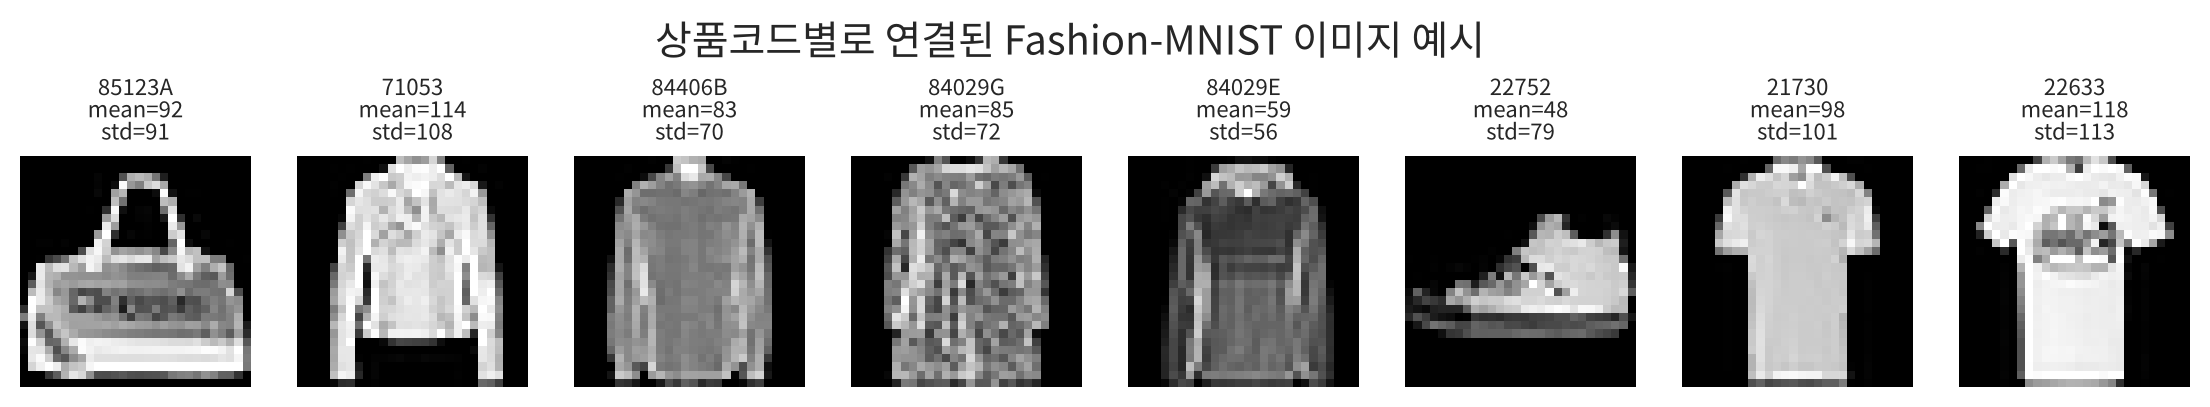

In [9]:
# 반복문 계산 결과와 axis 연산 결과가 같은지 상품 3개로 확인한다.
sample = image_features.head(3)
loop_means = [images[index].astype(float).mean()
              for index in sample["image_index"]]
print("axis 연산:", sample["image_mean"].round(4).tolist())
print("반복문   :", np.round(loop_means, 4).tolist())

# 이미지 8장과 계산된 평균·표준편차를 함께 본다.
fig, axes = plt.subplots(1, 8, figsize=(14, 2.6))
for ax, (_, row) in zip(axes, image_features.head(8).iterrows()):
    ax.imshow(images[row["image_index"]], cmap="gray")
    ax.set_title(f"{row['StockCode']}\nmean={row['image_mean']:.0f}\n"
                 f"std={row['image_std']:.0f}", fontsize=8)
    ax.axis("off")
fig.suptitle("상품코드별로 연결된 Fashion-MNIST 이미지 예시")
save_figure(fig, "00_image_samples.png")
plt.show()

### 해석

- 4,070개 상품에 서로 다른 이미지가 1장씩 연결됐다. 반복문으로 하나씩 계산한 값과 axis 연산 값이 소수점 넷째 자리까지 같다(예: 91.7883). 벡터화는 계산 결과를 바꾸지 않고 반복을 NumPy 내부로 옮길 뿐이다.
- 예시 이미지에서 밝은 옷일수록 `image_mean`이 크고, 배경(0)과 옷의 경계가 뚜렷할수록 `image_std`가 크다. **시사점**: 이미지 한 장(784개 픽셀)이 숫자 2개로 요약돼 표 데이터의 다른 컬럼과 같은 방식으로 통계·상관 분석을 할 수 있게 된다.

## 4. 분석 대상 거래 고르기

RFM은 '고객이 실제로 산 기록'으로 계산해야 한다. `filter_valid_transactions()`는 아래 행을 순서대로 제외하고, 고객의 취소 주문은 따로 보관해 8절에서 구매 금액에서 뺀다.

1. 고객 ID 없음 → 누가 샀는지 모름
2. 취소 주문(C로 시작) → 구매가 아니라 구매의 되돌림
3. 수량 0 이하 → 반품·조정
4. 상품코드가 숫자 5자리로 시작하지 않음 → 배송비(POST)·수수료(M, BANK CHARGES 등)

In [10]:
filter_report = analyzer.filter_valid_transactions()
filter_report

{'no_customer': 135080,
 'cancelled': 8905,
 'non_positive_qty': 0,
 'non_product_code': 1554,
 'kept_cancellations': 8539,
 'remaining_rows': 396370}

### 해석

- 541,909행 중 396,370행(73.1%)이 남았다. 고객 ID 없음 135,080행, 취소 8,905행, 상품 아닌 코드 1,554행이 빠졌다. 수량 0 이하는 앞 조건에서 이미 모두 걸러져 0건이다.
- 고객의 상품 취소 8,539행은 버리지 않고 보관했다. **시사점**: 취소를 그냥 지우면 '샀다가 전부 취소한 고객'이 큰 구매 고객으로 잡힌다. 예를 들어 고객 12346은 77,183파운드어치를 사고 같은 날 전량 취소했다. 그래서 8절의 Monetary는 순구매액(구매 − 취소)으로 계산한다.

## 5. IQR 이상치 탐지와 처리

IQR(사분위 범위) = Q3 − Q1이다. `Q1 − 1.5×IQR`보다 작거나 `Q3 + 1.5×IQR`보다 크면 이상치로 본다. 계산은 `pipeline.py`의 `calculate_iqr_bounds()` 함수가 직접 한다.

처리 방법은 **삭제 대신 경계값으로 자르기(clipping)**를 택했다. 큰 주문을 지우면 실제 도매 거래까지 사라지기 때문이다. 자른 데이터(`clipped_df`)는 분포·상관 분석에만 쓰고, RFM 금액은 원본으로 계산한다.

In [11]:
OUTLIER_COLUMNS = ["Quantity", "UnitPrice", "Amount"]
outlier_rows = []
for column in OUTLIER_COLUMNS:
    outliers, lower, upper = analyzer.detect_outliers(
        column, threshold=IQR_MULTIPLIER)
    outlier_rows.append({
        "column": column, "lower": lower, "upper": upper,
        "outlier_count": len(outliers),
        "outlier_pct": len(outliers) / len(analyzer.df) * 100,
        "max_value": analyzer.df[column].max(),
    })
outlier_table = pd.DataFrame(outlier_rows).set_index("column")
outlier_table

,lower,upper,outlier_count,outlier_pct,max_value
column,,,,,
Quantity,-13.00,27.00,25629,6.47,"80,995.00"
UnitPrice,-2.50,7.50,33032,8.33,649.50
Amount,-18.00,42.48,30501,7.70,"168,469.60"


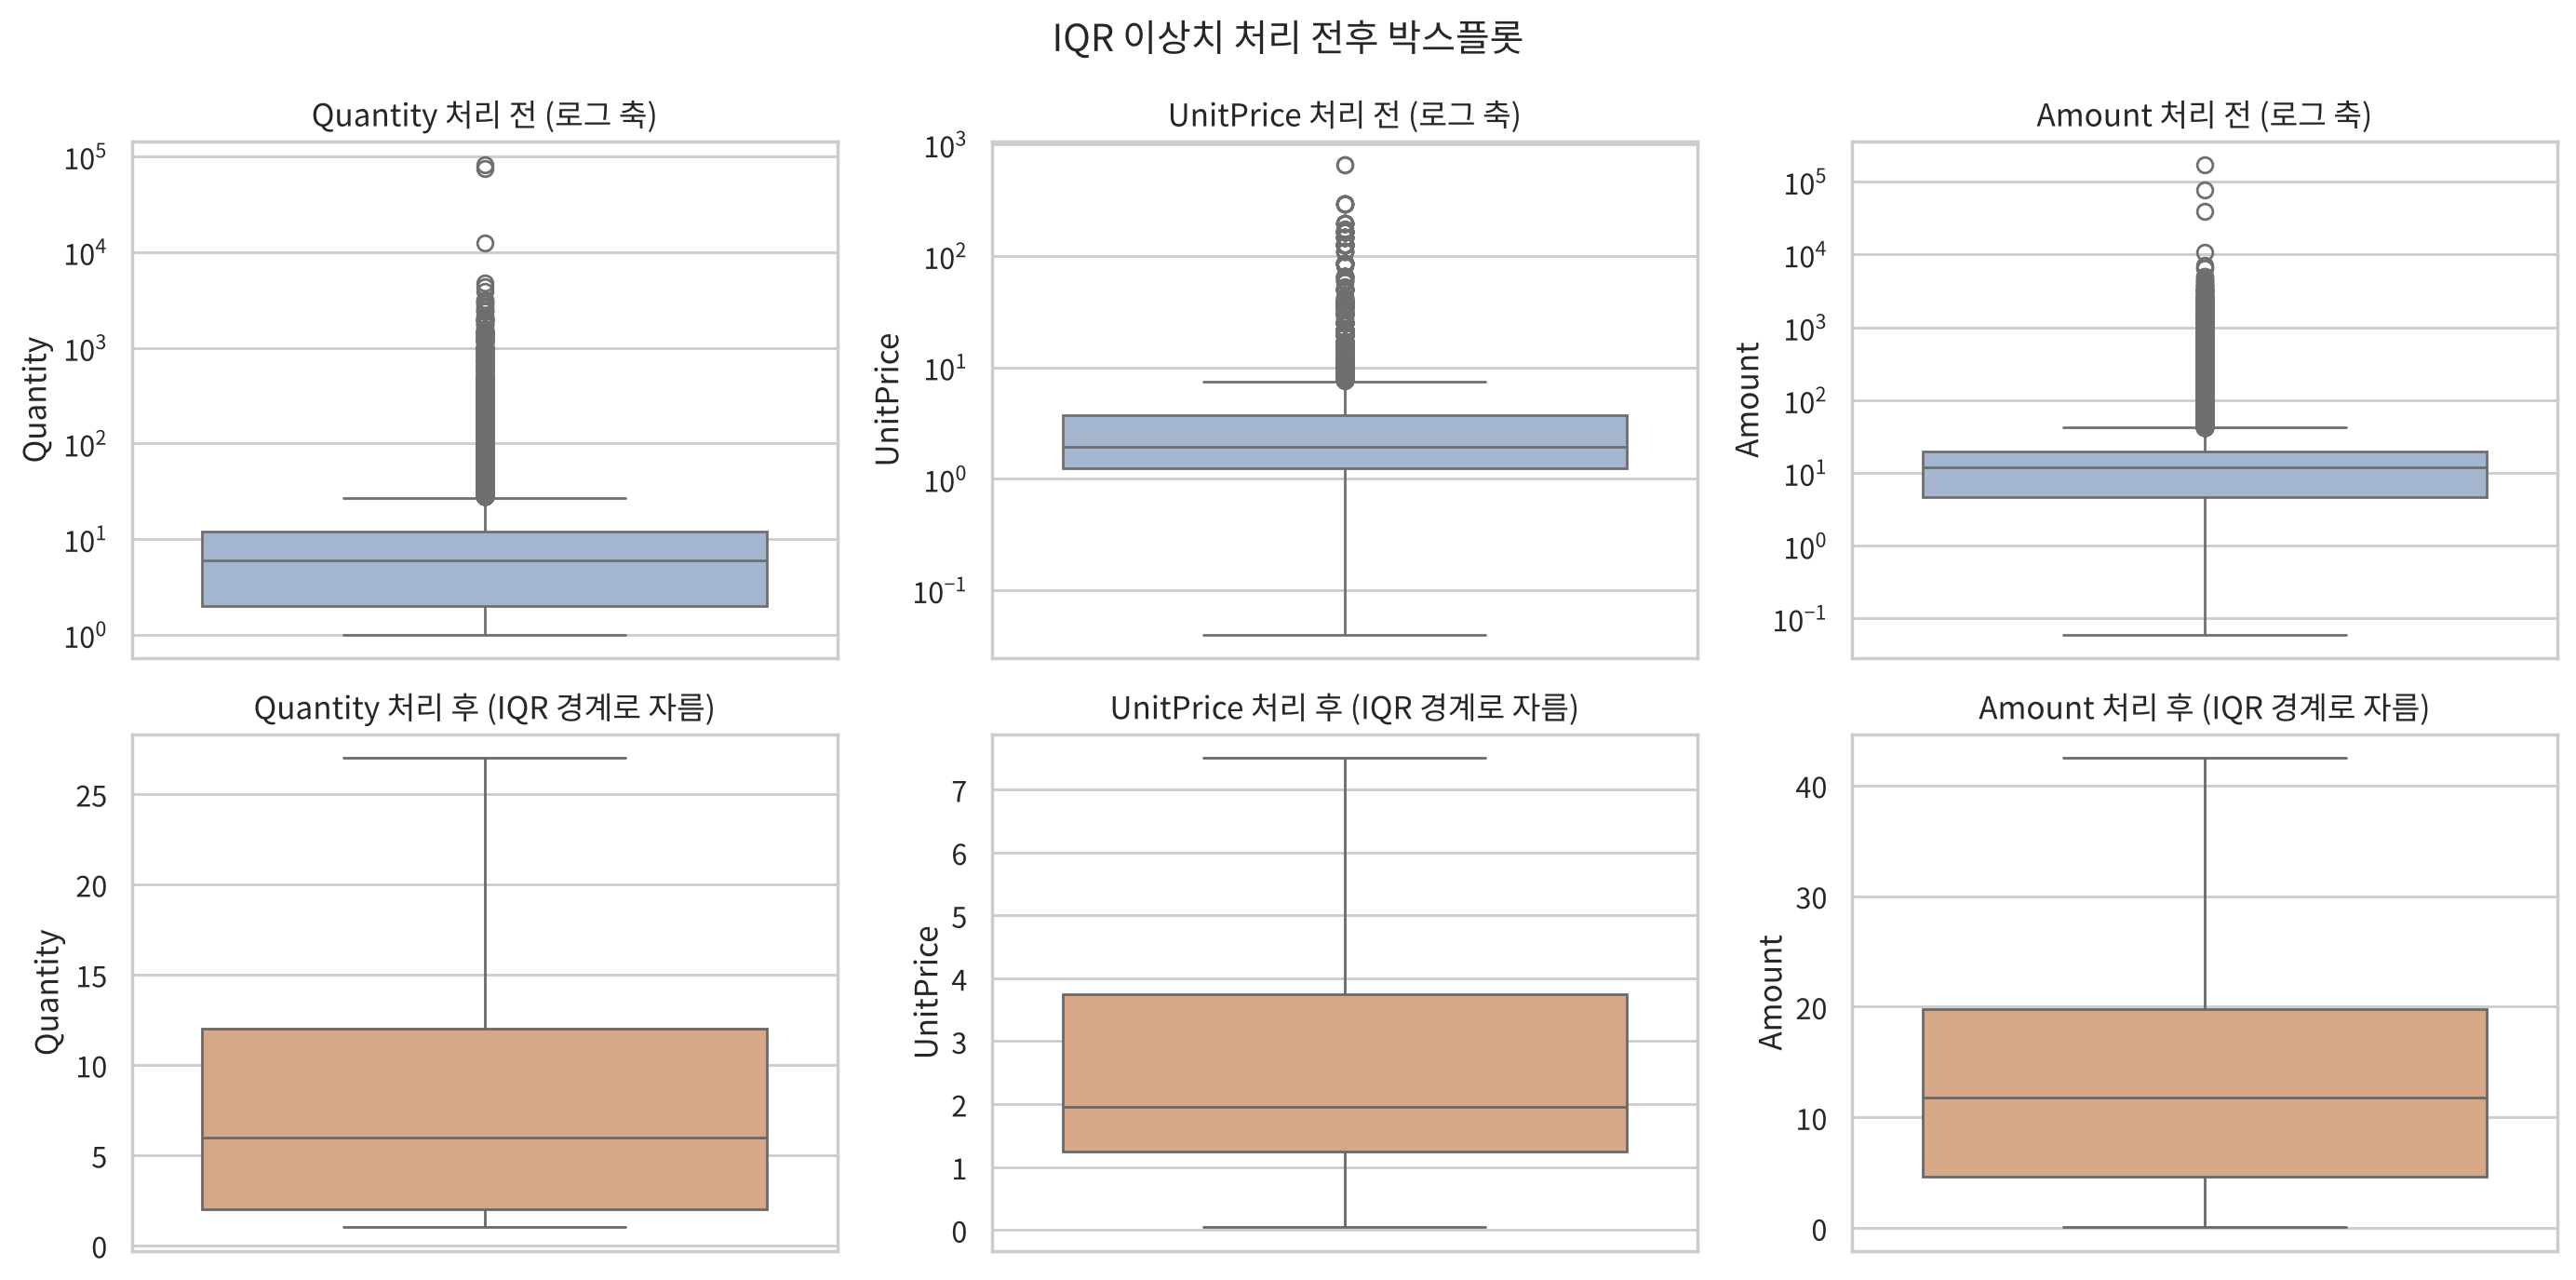

In [12]:
clipped_df = analyzer.clip_outliers(OUTLIER_COLUMNS,
                                    threshold=IQR_MULTIPLIER)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col_index, column in enumerate(OUTLIER_COLUMNS):
    before_ax = axes[0, col_index]
    after_ax = axes[1, col_index]
    sns.boxplot(y=analyzer.df[column], ax=before_ax, color="#9db4d6")
    sns.boxplot(y=clipped_df[column], ax=after_ax, color="#e3a67a")
    # 처리 전은 값 범위가 수만 배 차이 나서 로그 축으로 그린다.
    before_ax.set_yscale("log")
    before_ax.set_title(f"{column} 처리 전 (로그 축)")
    after_ax.set_title(f"{column} 처리 후 (IQR 경계로 자름)")
    before_ax.set_ylabel(column)
    after_ax.set_ylabel(column)
fig.suptitle("IQR 이상치 처리 전후 박스플롯")
fig.tight_layout()
save_figure(fig, "02_boxplot_outlier_before_after.png")
plt.show()

In [13]:
pd.concat({
    "before": analyzer.summarize_numeric(OUTLIER_COLUMNS),
    "after": analyzer.summarize_numeric(OUTLIER_COLUMNS, data=clipped_df),
}, axis=1)

before                          after                        
            mean median    std   q1    q3  mean median   std   q1    q3
Quantity   13.05   6.00 180.73 2.00 12.00  8.34   6.00  8.10 2.00 12.00
UnitPrice   2.87   1.95   4.26 1.25  3.75  2.58   1.95  2.09 1.25  3.75
Amount     22.14  11.80 309.35 4.68 19.80 14.32  11.80 11.93 4.68 19.80

### 해석

- 상한은 Quantity 27개, UnitPrice 7.50파운드, Amount 42.48파운드다. 이를 넘는 행이 각각 6.47%, 8.33%, 7.70%다. 하한은 모두 음수라 정상 구매에서는 하한 쪽 이상치가 없다.
- 처리 후 Quantity 표준편차가 180.73 → 8.10, Amount는 309.35 → 11.93으로 줄었다. 반면 중앙값(6개, 11.80파운드)과 Q1·Q3는 그대로다. 평균과 표준편차는 극단값 몇 개에 크게 끌려가고, 중앙값·사분위수는 거의 영향을 받지 않는다는 것을 보여 준다.
- 이 쇼핑몰은 도매 고객이 많아 '이상치'의 상당수가 실제 대량 주문이다. **시사점**: IQR 이상치는 '오류'가 아니라 '분포 밖의 값'이므로, 지우기 전에 업무 의미를 먼저 확인해야 한다. 여기서는 RFM에 원본 금액을 쓰고, 대량 주문 고객은 오히려 VIP 후보로 본다.

## 6. 기술 통계와 분포

주요 수치형 변수의 평균·중앙값·표준편차·사분위수를 보고, 히스토그램으로 분포 모양을 확인한다. 히스토그램은 이상치 처리 후 데이터나 로그 축을 써서 대부분의 값이 보이게 했다.

In [14]:
NUMERIC_COLUMNS = ["Quantity", "UnitPrice", "Amount", "desc_word_count",
                   "desc_length", "image_mean", "image_std"]
analyzer.summarize_numeric(NUMERIC_COLUMNS)

,mean,median,std,q1,q3
Quantity,13.05,6.00,180.73,2.00,12.00
UnitPrice,2.87,1.95,4.26,1.25,3.75
Amount,22.14,11.80,309.35,4.68,19.80
desc_word_count,4.41,4.00,1.08,4.00,5.00
desc_length,26.53,27.00,5.23,23.00,31.00
image_mean,73.18,68.26,32.44,47.23,98.51
image_std,81.85,84.57,19.95,67.56,98.71


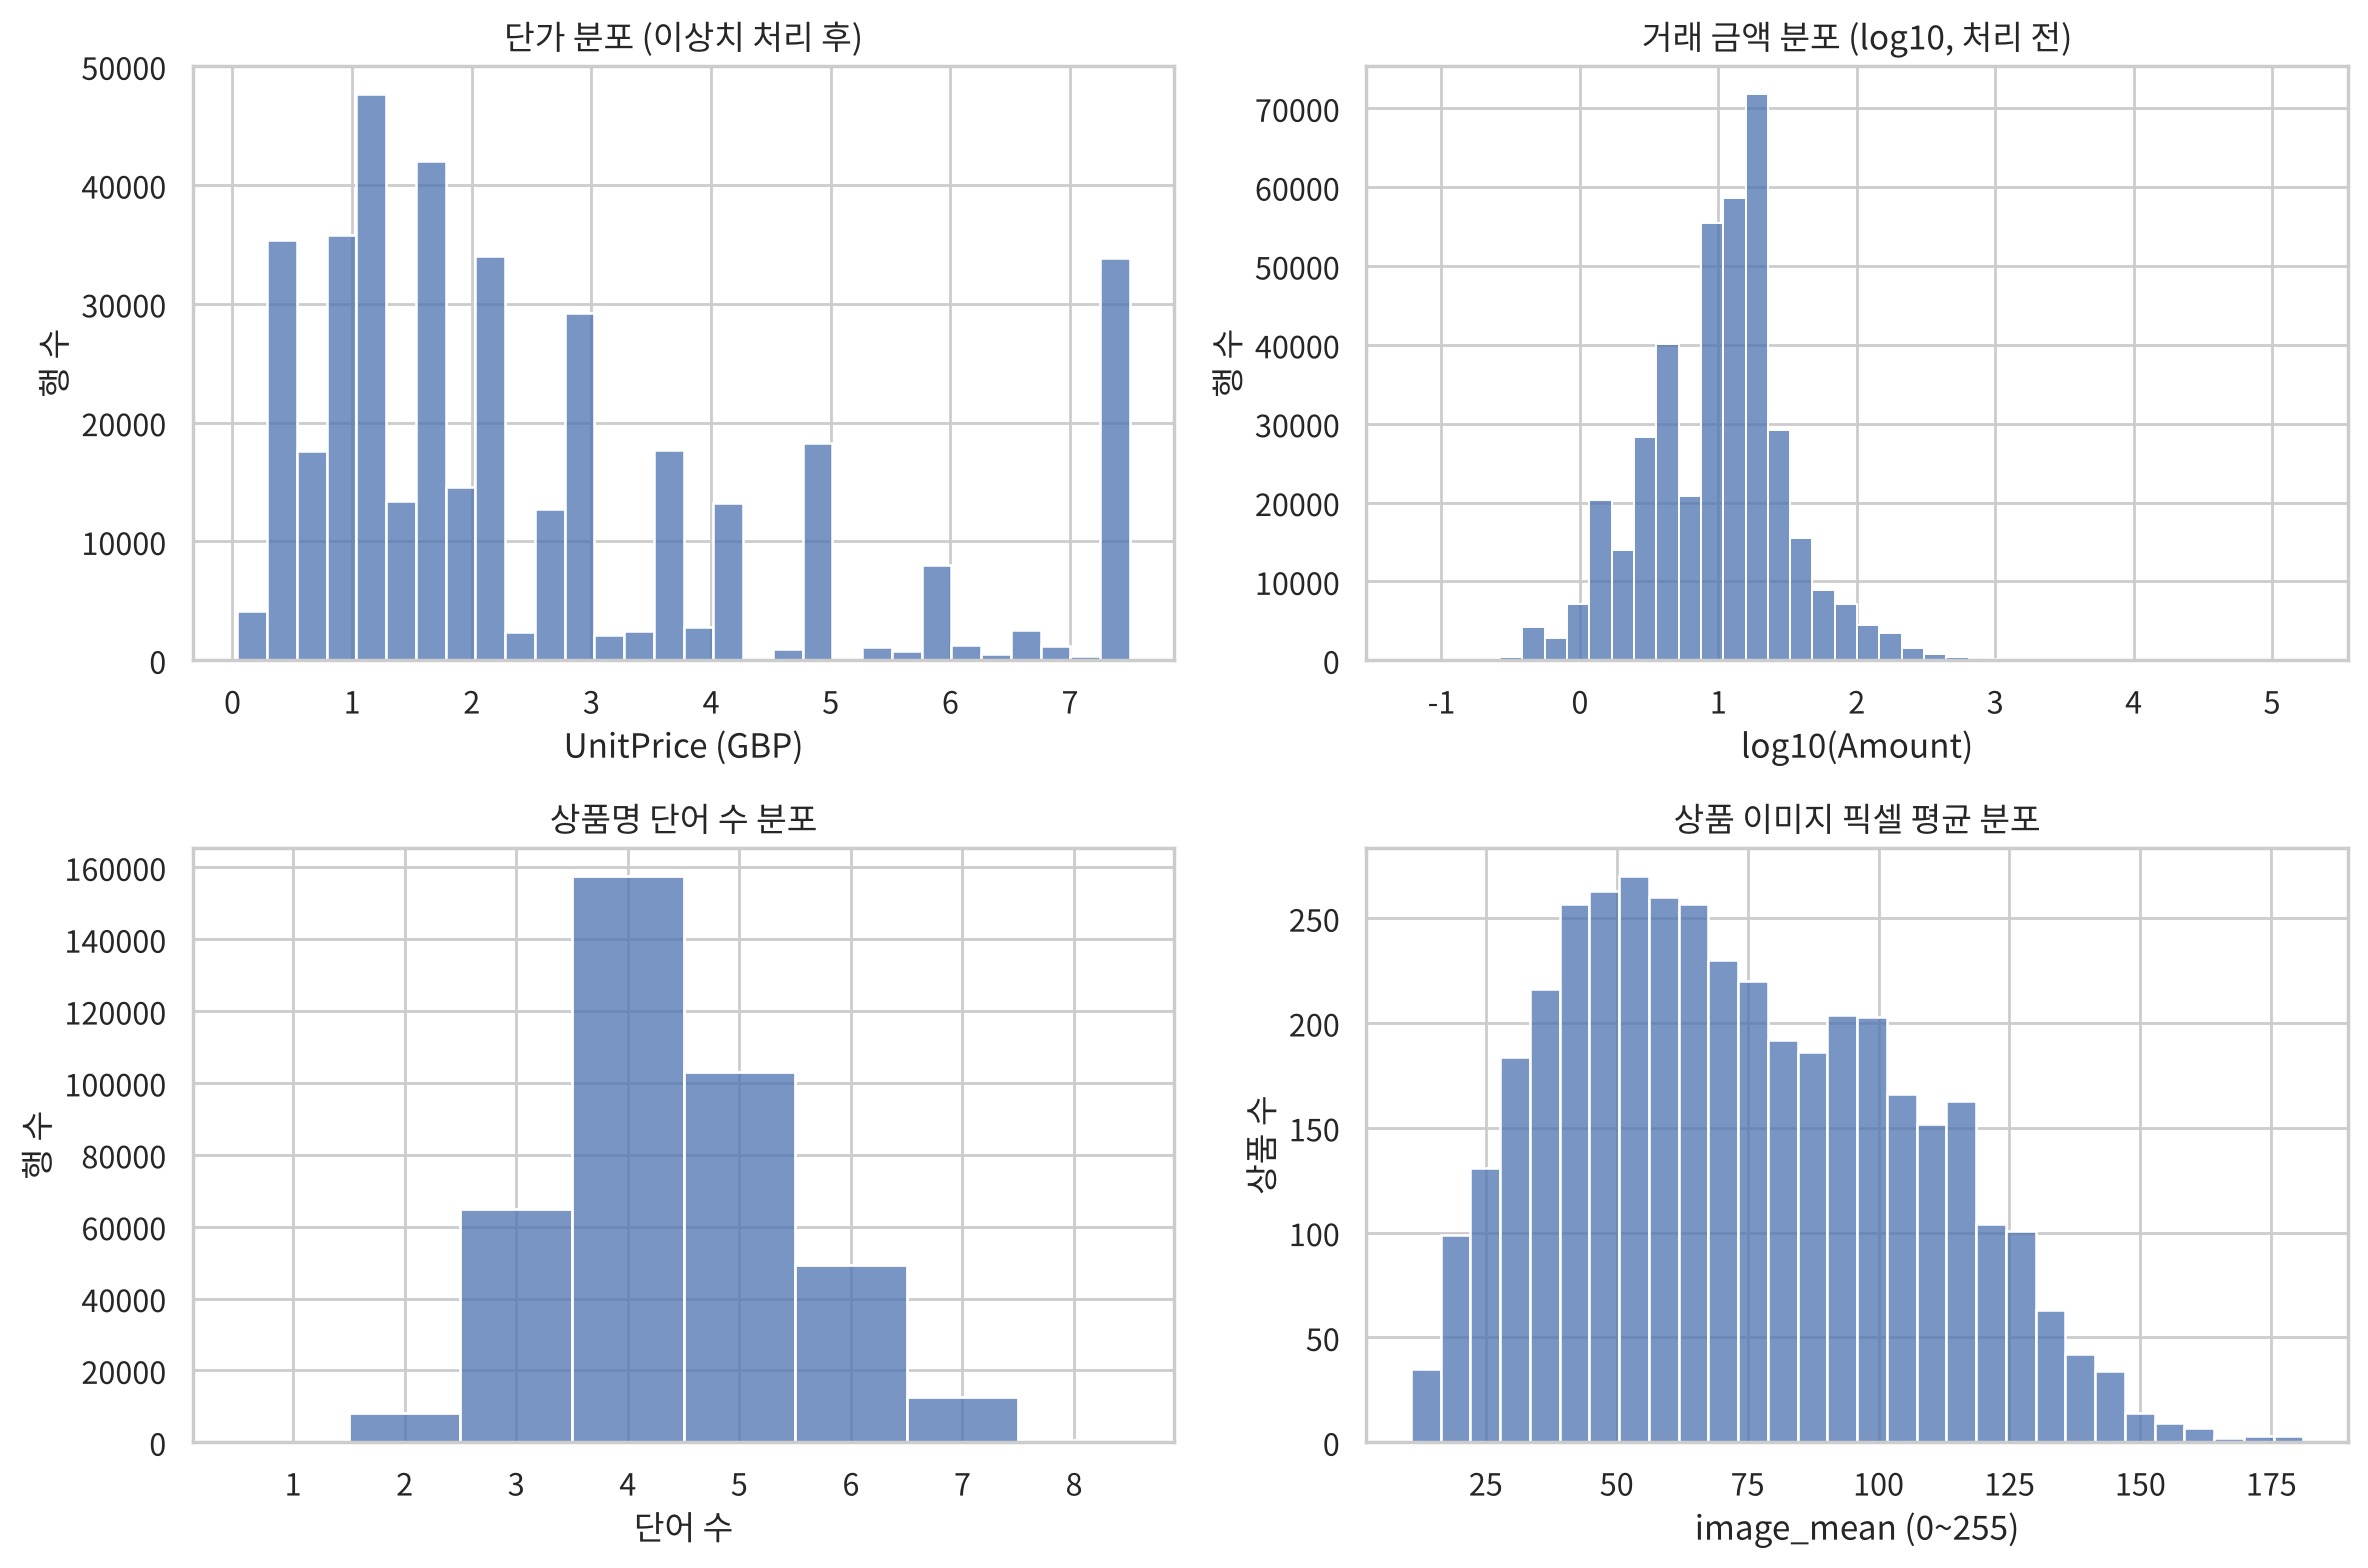

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(clipped_df["UnitPrice"], bins=30, ax=axes[0, 0])
axes[0, 0].set(title="단가 분포 (이상치 처리 후)",
               xlabel="UnitPrice (GBP)", ylabel="행 수")
sns.histplot(np.log10(analyzer.df["Amount"]), bins=40, ax=axes[0, 1])
axes[0, 1].set(title="거래 금액 분포 (log10, 처리 전)",
               xlabel="log10(Amount)", ylabel="행 수")
sns.histplot(analyzer.df["desc_word_count"], discrete=True, ax=axes[1, 0])
axes[1, 0].set(title="상품명 단어 수 분포",
               xlabel="단어 수", ylabel="행 수")
sns.histplot(image_features["image_mean"], bins=30, ax=axes[1, 1])
axes[1, 1].set(title="상품 이미지 픽셀 평균 분포",
               xlabel="image_mean (0~255)", ylabel="상품 수")
fig.tight_layout()
save_figure(fig, "01_histograms.png")
plt.show()

### 해석

- **수량·금액은 오른쪽 꼬리가 긴 분포다.** Quantity 평균 13.05개가 중앙값 6개의 두 배를 넘고, Amount도 평균 22.14파운드 대 중앙값 11.80파운드다. log10(Amount) 히스토그램은 1(=10파운드) 부근에 몰려 있다. **시사점**: 이 데이터의 '보통 주문 한 줄'은 평균보다 중앙값(약 12파운드)으로 설명하는 것이 정확하다.
- **단가는 저가 위주다.** 중앙값 1.95파운드, Q3 3.75파운드다. 처리 후 히스토그램 오른쪽 끝 7.5파운드의 막대는 상한으로 잘린 8.33%의 행이 모인 것이다. **시사점**: 1~2파운드대 소품이 주력이므로 객단가를 올리려면 단가보다 수량(묶음 구매)을 늘리는 쪽이 현실적이다.
- **상품명은 대부분 4~5단어, 23~31글자(Q1~Q3)다.** 표준편차가 1.08단어로 작아 상품명 길이로 상품을 구분하기는 어렵다.
- **이미지 밝기(image_mean)는 평균 73.18, 표준편차 32.44**로 어두운 쪽(0에 가까운 배경)이 많은 분포다. Fashion-MNIST는 검은 배경에 옷이 있는 이미지라 자연스러운 결과다.

## 7. 상관 분석

두 가지 상관계수를 비교한다.

- **Pearson**: 직선 관계의 세기. 극단값에 민감하다.
- **Spearman**: 값의 순위끼리의 관계. 한쪽이 커질 때 다른 쪽도 커지는지(단조 관계)를 보며 극단값에 강하다.

상관은 함께 움직이는 정도일 뿐 원인과 결과를 뜻하지 않는다.

In [16]:
pearson_raw = analyzer.calculate_correlations(NUMERIC_COLUMNS)
spearman_clipped = analyzer.calculate_correlations(
    NUMERIC_COLUMNS, data=clipped_df, method="spearman")

pairs = [("Quantity", "Amount"), ("Quantity", "UnitPrice"),
         ("UnitPrice", "Amount"), ("image_mean", "image_std"),
         ("desc_length", "UnitPrice")]
pd.DataFrame({
    "pair": [f"{a} - {b}" for a, b in pairs],
    "pearson_raw": [pearson_raw.loc[a, b] for a, b in pairs],
    "spearman_clipped": [spearman_clipped.loc[a, b] for a, b in pairs],
}).set_index("pair").round(3)

,pearson_raw,spearman_clipped
pair,,
Quantity - Amount,0.92,0.66
Quantity - UnitPrice,-0.02,-0.41
UnitPrice - Amount,0.07,0.34
image_mean - image_std,0.77,0.80
desc_length - UnitPrice,-0.02,-0.03


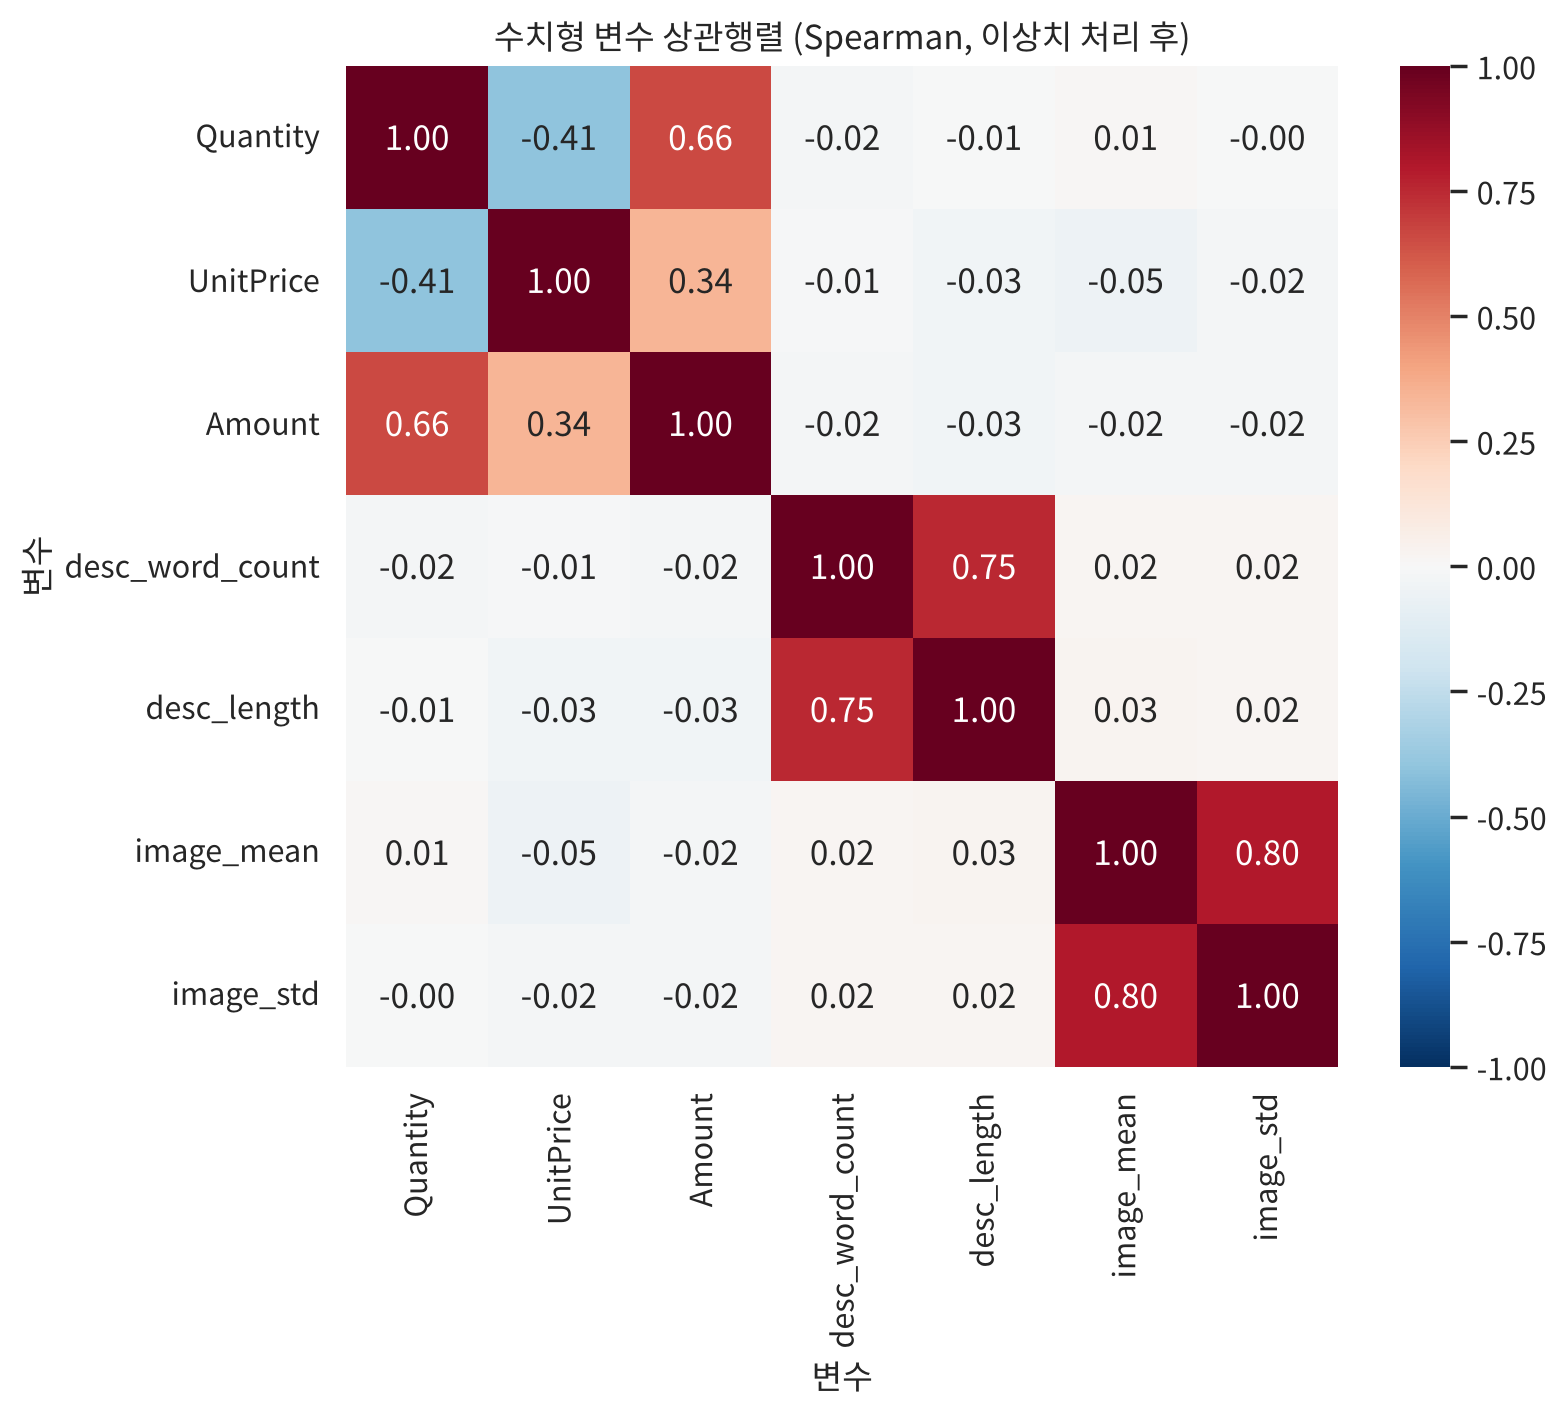

In [17]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(spearman_clipped, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, ax=ax)
ax.set(title="수치형 변수 상관행렬 (Spearman, 이상치 처리 후)",
       xlabel="변수", ylabel="변수")
save_figure(fig, "04_heatmap_correlation.png")
plt.show()

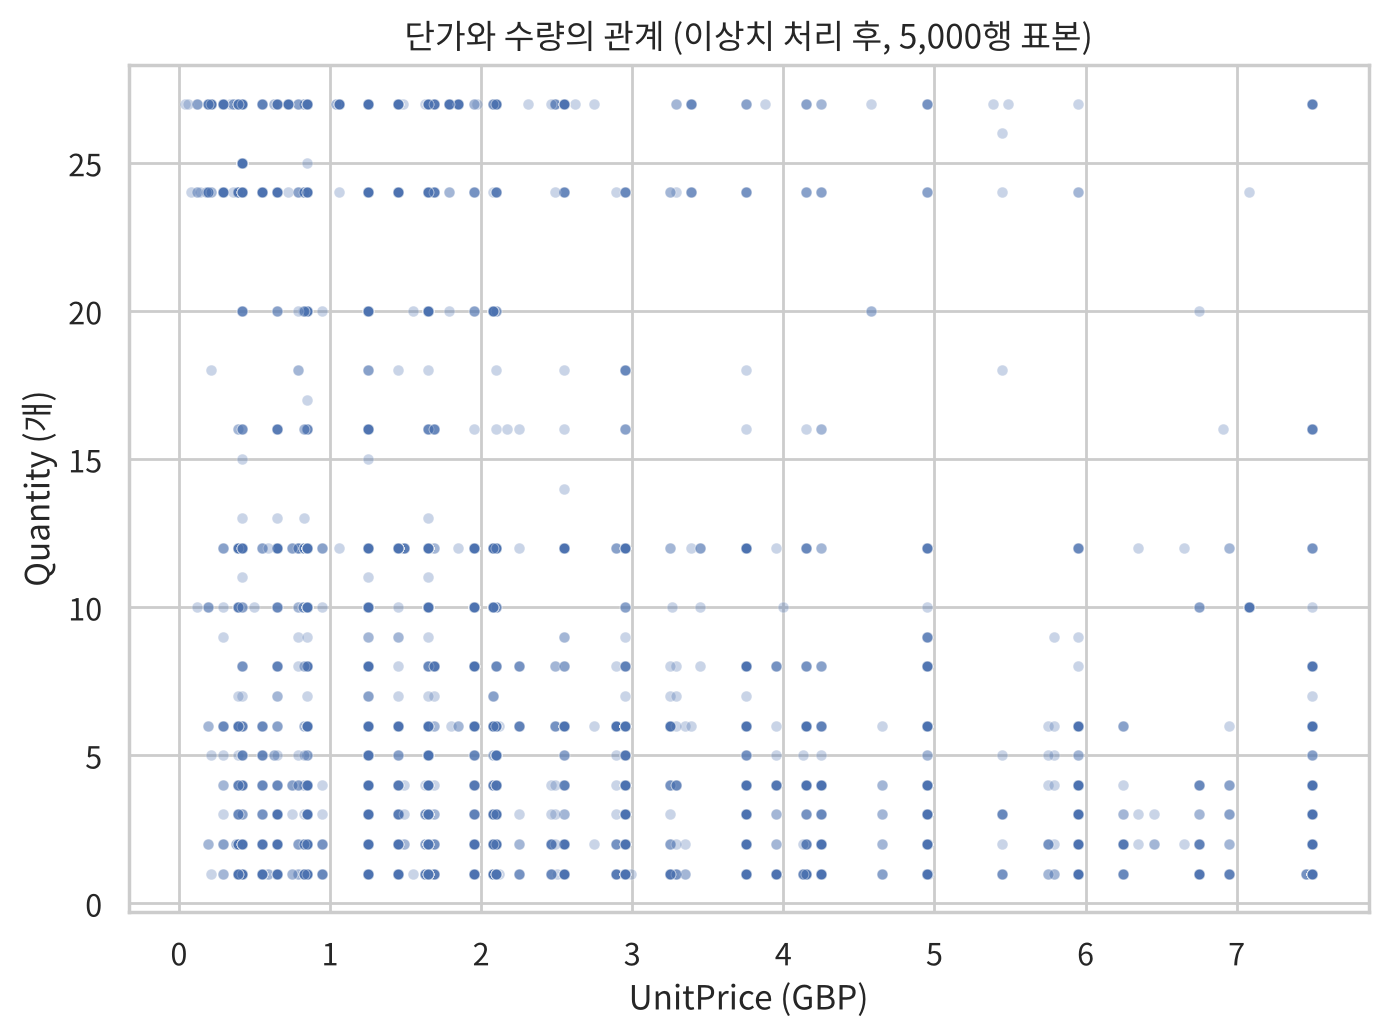

In [18]:
scatter_sample = clipped_df.sample(5000, random_state=RANDOM_SEED)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=scatter_sample, x="UnitPrice", y="Quantity",
                alpha=0.3, s=15, ax=ax)
ax.set(title="단가와 수량의 관계 (이상치 처리 후, 5,000행 표본)",
       xlabel="UnitPrice (GBP)", ylabel="Quantity (개)")
save_figure(fig, "05_scatter_price_quantity.png")
plt.show()

### 해석 (5쌍)

| 변수 쌍 | Pearson(원본) | Spearman(처리 후) | 해석과 시사점 |
| --- | --- | --- | --- |
| Quantity - Amount | 0.92 | 0.66 | 금액은 수량에 크게 좌우된다. 원본 Pearson이 더 높은 것은 초대형 주문 몇 건이 직선 관계를 과장하기 때문이다. 매출을 늘리려면 수량을 움직이는 프로모션이 효과적일 가능성이 높다. |
| Quantity - UnitPrice | -0.02 | -0.41 | 원본에서는 관계가 없어 보이지만, 순위로 보면 비싼 상품일수록 적게 산다. 극단값이 실제 관계를 가린 사례다. 저가 상품은 묶음 판매, 고가 상품은 단품 판매 전략이 맞다. |
| UnitPrice - Amount | 0.07 | 0.34 | 단가가 높다고 주문 금액이 크게 늘지는 않는다. 수량이 줄어 상쇄되기 때문이다. |
| image_mean - image_std | 0.77 | 0.80 | 밝은 옷 이미지일수록 검은 배경과의 대비가 커져 표준편차도 크다. 두 피처가 비슷한 정보를 담고 있으므로 모델에 넣을 때 중복을 고려해야 한다. |
| desc_length - UnitPrice | -0.02 | -0.03 | 상품명이 길다고 비싸지 않다. 상품명 길이는 가격 예측에 쓸모가 거의 없다. |

산점도에서도 2파운드 미만 구간에는 24~27개 대량 주문 점이 많고, 5파운드 이상 구간은 수량이 대부분 12개 이하에 몰려 있어 음의 순위 상관을 눈으로 확인할 수 있다. 이미지 피처와 매출 변수의 상관이 모두 0에 가까운 것은 이미지를 무작위로 연결했기 때문이며, 실제 상품 사진이라면 다시 분석해야 한다.

## 8. 범주형·시계열 분석

국가별 주문 수(막대그래프)와 월별 매출 추이(라인차트)를 본다. 매출은 4절에서 고른 정상 구매 기준이다.

영국 주문 비중: 90.1%


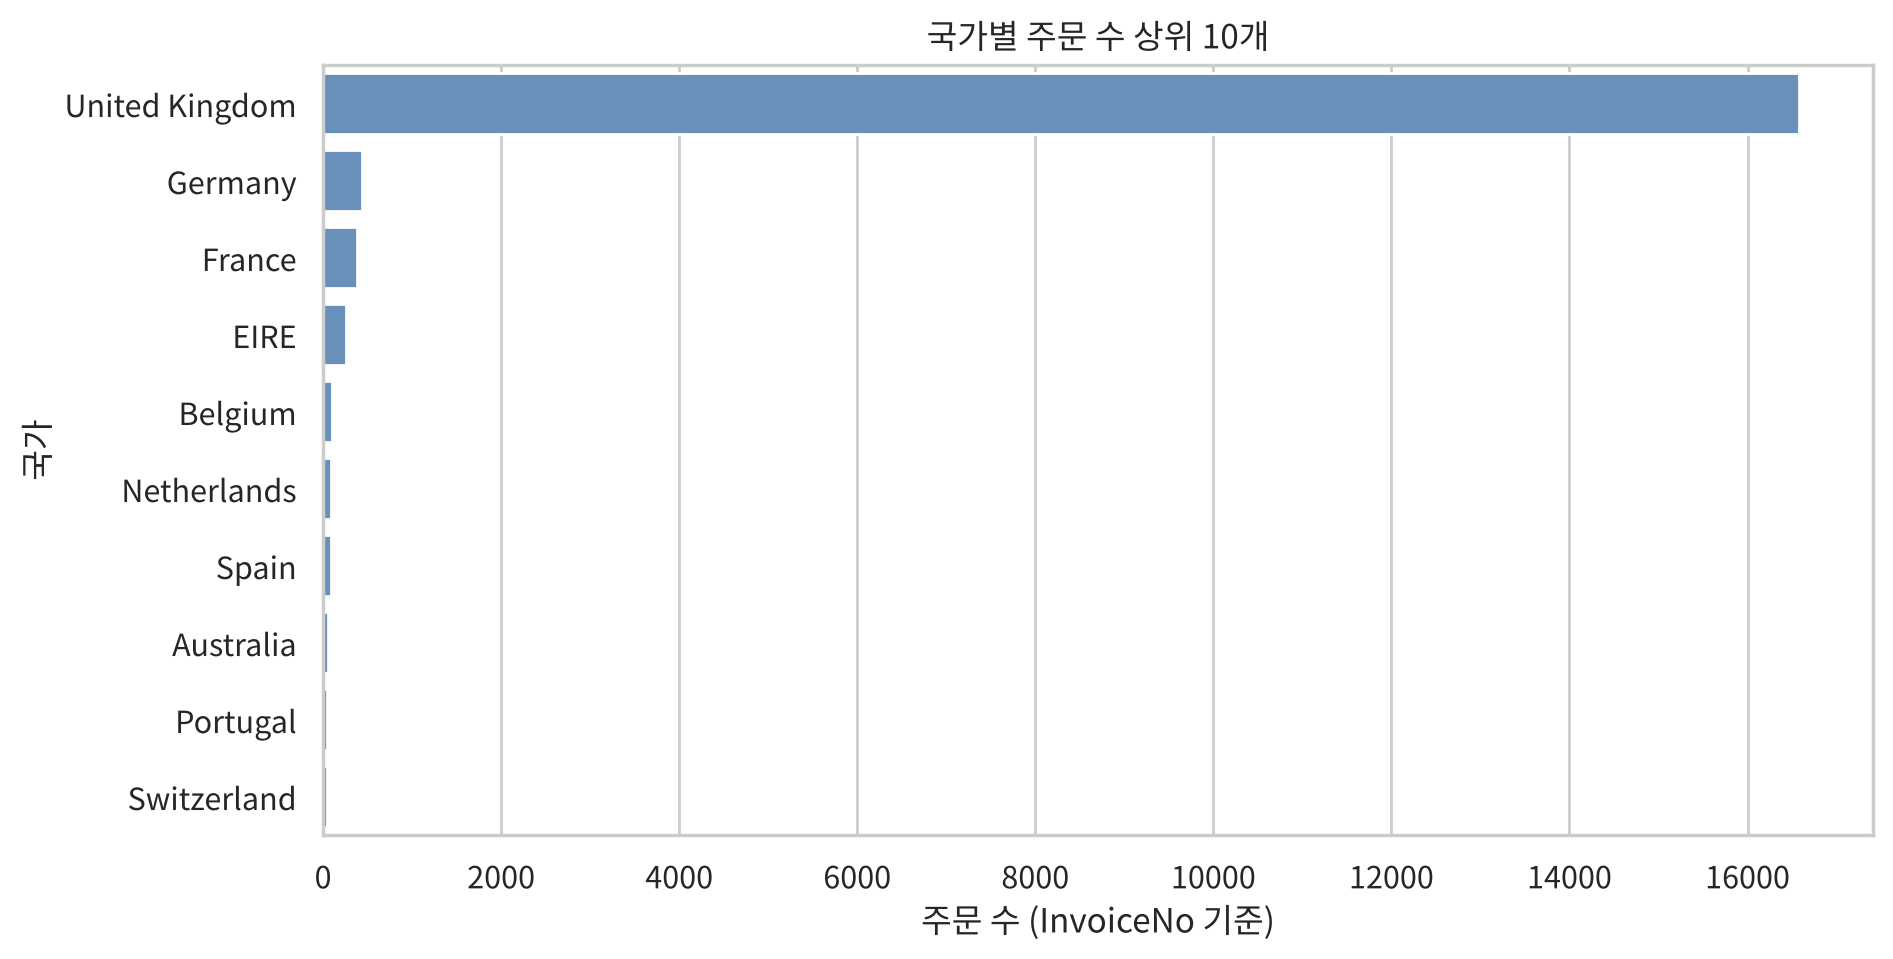

In [19]:
country_orders = (analyzer.df.groupby("Country")["InvoiceNo"]
                  .nunique().sort_values(ascending=False).head(10))
uk_share = country_orders.iloc[0] / analyzer.df["InvoiceNo"].nunique() * 100
print(f"영국 주문 비중: {uk_share:.1f}%")

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=country_orders.values, y=country_orders.index, ax=ax,
            color="#5b8fc9")
ax.set(title="국가별 주문 수 상위 10개", xlabel="주문 수 (InvoiceNo 기준)",
       ylabel="국가")
save_figure(fig, "03_bar_country_orders.png")
plt.show()

,revenue,orders,avg_order_value
InvoiceDate,,,
2010-12-01,"567,649.97",1394,407.21
2011-01-01,"564,145.54",983,573.90
2011-02-01,"443,356.42",993,446.48
2011-03-01,"584,600.98",1312,445.58
2011-04-01,"455,281.99",1139,399.72
2011-05-01,"660,801.70",1544,427.98
2011-06-01,"654,432.56",1390,470.81
2011-07-01,"592,788.60",1321,448.74
2011-08-01,"638,140.20",1268,503.27


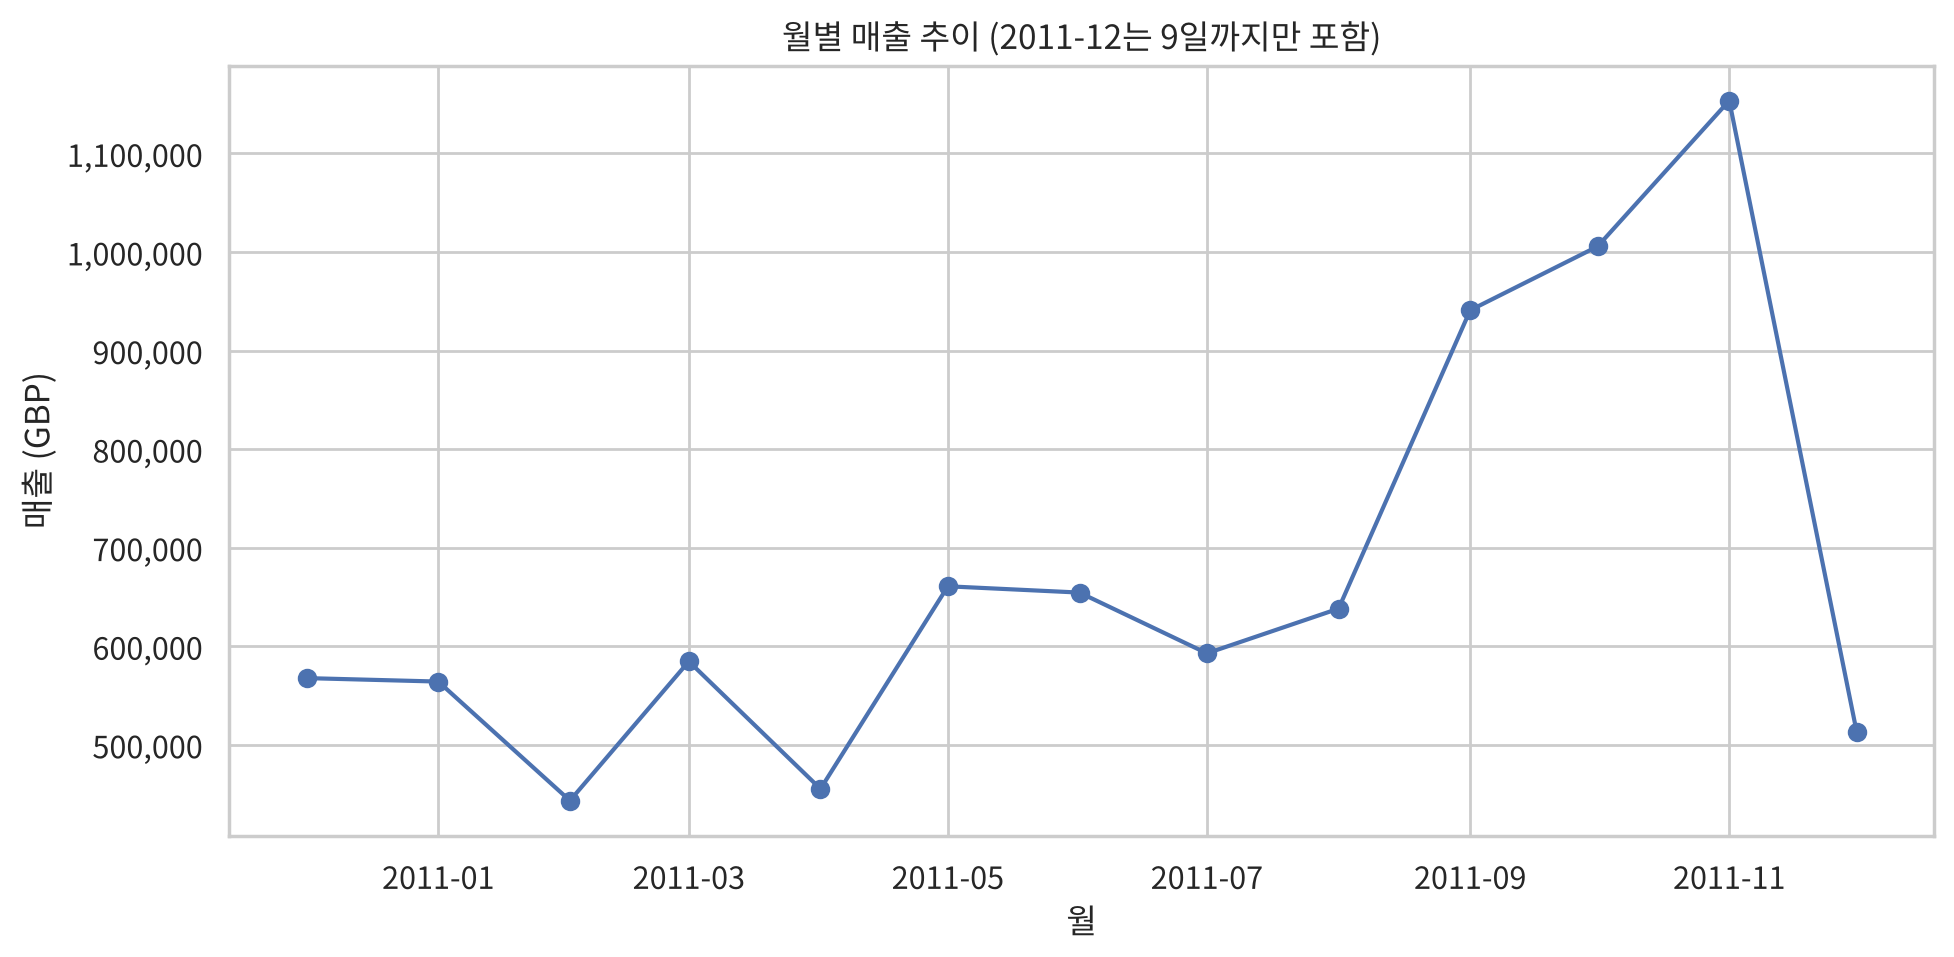

In [20]:
monthly = analyzer.calculate_monthly_revenue()
monthly["avg_order_value"] = monthly["revenue"] / monthly["orders"]
display(monthly)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly["revenue"], marker="o")
ax.set(title="월별 매출 추이 (2011-12는 9일까지만 포함)",
       xlabel="월", ylabel="매출 (GBP)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
save_figure(fig, "06_line_monthly_revenue.png")
plt.show()

### 해석

- **국가**: 영국 주문이 전체 주문의 90.1%다. 그다음은 독일·프랑스·아일랜드(EIRE)지만 주문 수 차이가 크다. **시사점**: 이 분석의 고객 세분화 결과는 사실상 영국 고객의 행동이며, 해외 고객 전략은 국가별로 따로 봐야 한다.
- **월별 매출**: 2011-09부터 매출이 급증해 11월에 1,153,596파운드로 가장 높다. 이는 2011-02(443,356파운드)의 약 2.6배다. 11월 주문 수도 2,643건으로 가장 많다. **시사점**: 크리스마스 선물 수요가 9~11월에 몰리므로 재고·마케팅 예산을 3분기 말부터 집중해야 한다.
- 2011-12는 9일까지만 기록돼 있어 매출이 낮게 보인다. 실제 감소가 아니므로 추세 판단에서 제외한다.

## 9. RFM 고객 세분화

| 지표 | 정의 | 좋은 방향 |
| --- | --- | --- |
| Recency | 기준일(2011-12-09) − 마지막 구매일 (일) | 작을수록 |
| Frequency | 서로 다른 주문번호 수 | 클수록 |
| Monetary | 구매 금액 − 취소 금액 (순구매액) | 클수록 |

각 지표를 고객 순위 기준 5개 구간(분위수)으로 나눠 1~5점을 준다. 1회 구매 고객이 많아 Frequency 값이 겹치므로 `rank(method="first")`로 순위를 먼저 매긴 뒤 나눈다. 세그먼트 규칙은 다음과 같고 위에서부터 먼저 맞는 규칙을 적용한다.

| 세그먼트 | 규칙 | 의미 |
| --- | --- | --- |
| VIP | R≥4, F≥4, M≥4 | 최근에, 자주, 많이 산다 |
| Loyal | R≥3, F≥3 | 꾸준히 온다 |
| New | R≥4, F≤2 | 최근 왔지만 아직 횟수가 적다 |
| At Risk | R≤2, F≥3 | 예전엔 자주 왔는데 최근 뜸하다 |
| Churned | R≤2, F≤2 | 오래전에 조금 사고 오지 않는다 |
| Regular | 나머지 | 중간 고객 |

In [21]:
reference_date = analyzer.df["InvoiceDate"].max()
print("Recency 기준일(최종 거래일):", reference_date)

rfm = analyzer.calculate_rfm(reference_date=reference_date,
                             cancellations=analyzer.cancellations)
rfm = analyzer.segment_customers()
print("취소 차감 전 총 구매액:", f"{analyzer.df['Amount'].sum():,.0f}")
print("취소 금액 합계:", f"{analyzer.cancellations['Amount'].sum():,.0f}")
print("취소 차감 후 총 순구매액:", f"{rfm['Monetary'].sum():,.0f}")
print("순구매액 0 이하로 제외된 고객 수:", len(analyzer.rfm_excluded))
rfm.head()

Recency 기준일(최종 거래일): 2011-12-09 12:50:00
취소 차감 전 총 구매액: 8,774,578
취소 금액 합계: -474,403
취소 차감 후 총 순구매액: 8,304,335
순구매액 0 이하로 제외된 고객 수: 14


,Frequency,Monetary,Recency,R_score,F_score,M_score,RFM_score,Segment
CustomerID,,,,,,,,
12347,7,"4,310.00",1,5,5,5,15,VIP
12348,4,"1,437.24",74,2,4,4,10,At Risk
12349,1,"1,457.55",18,4,1,4,9,New
12350,1,294.40,309,1,1,2,4,Churned
12352,7,"1,265.41",35,3,5,4,12,Loyal


In [22]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,"4,321.00","4,321.00","4,321.00"
mean,91.53,4.26,"1,921.85"
std,100.12,7.65,"8,315.97"
min,0.00,1.00,2.90
25%,17.00,1.00,300.52
50%,50.00,2.00,654.60
75%,142.00,5.00,"1,611.59"
max,373.00,206.00,"279,611.78"


In [23]:
segment_summary = analyzer.summarize_segments()
segment_summary

,customers,avg_recency_days,avg_frequency,avg_monetary,total_monetary,customer_share_pct,revenue_share_pct
Segment,,,,,,,
VIP,941,11.48,11.12,"5,877.61","5,530,830.53",21.78,66.60
Loyal,995,32.32,3.74,"1,270.39","1,264,035.02",23.03,15.22
At Risk,656,149.07,3.40,"1,183.06","776,088.74",15.18,9.35
Churned,1072,216.08,1.10,401.92,"430,862.71",24.81,5.19
Regular,347,51.39,1.15,441.03,"153,038.80",8.03,1.84
New,310,17.04,1.25,482.19,"149,479.01",7.17,1.80


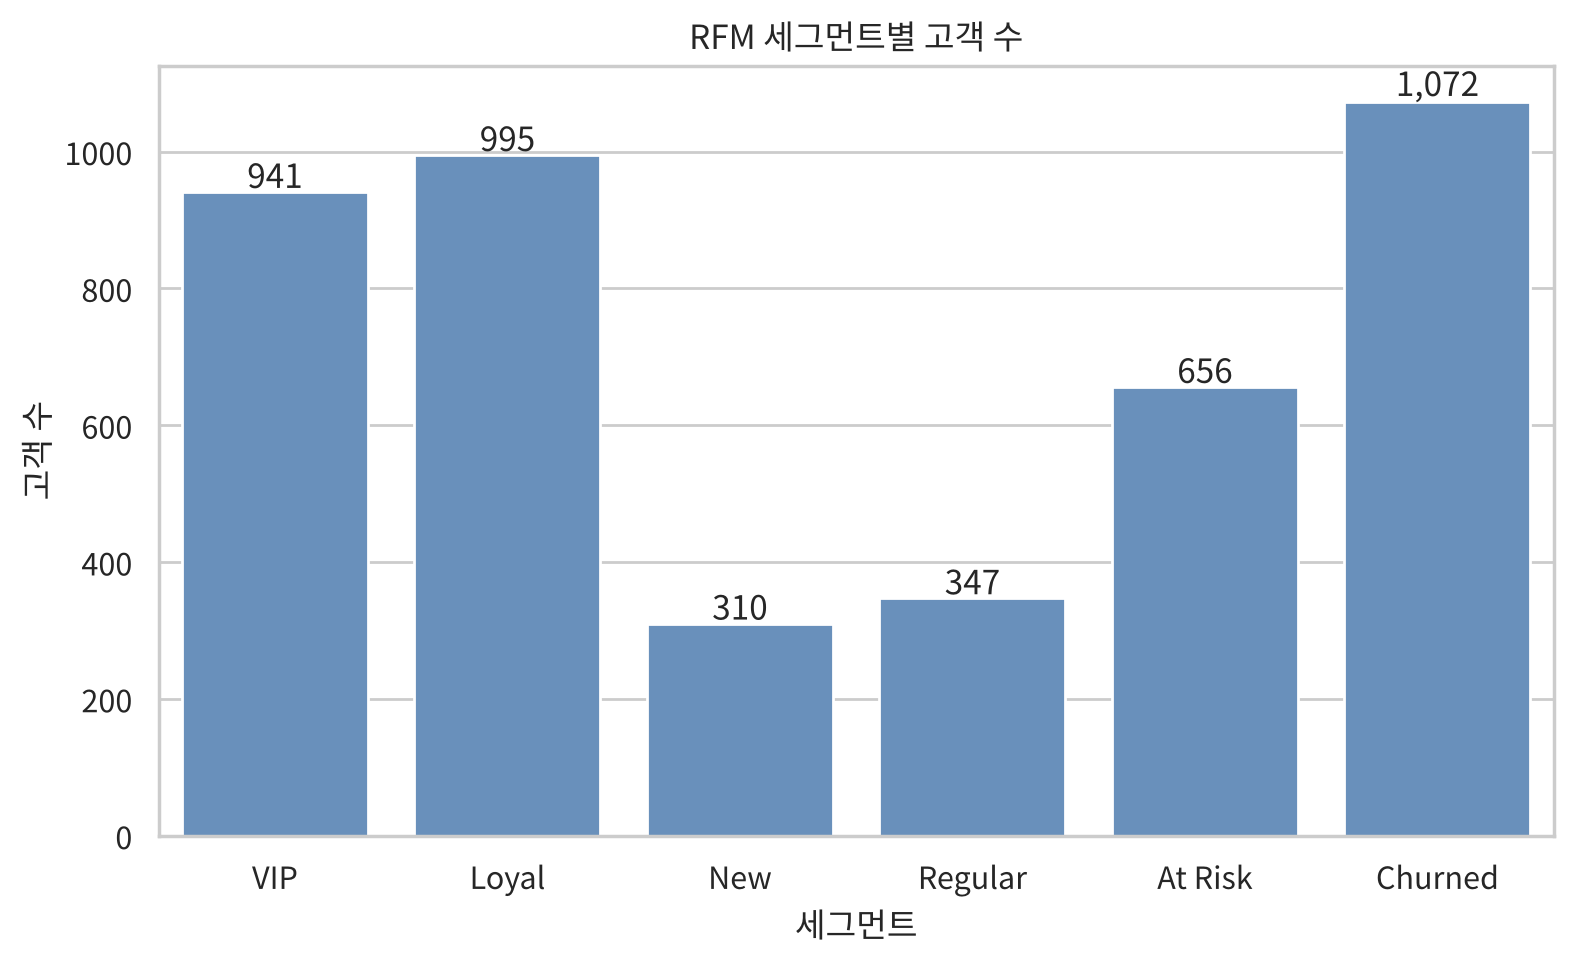

In [24]:
SEGMENT_ORDER = ["VIP", "Loyal", "New", "Regular", "At Risk", "Churned"]

fig, ax = plt.subplots(figsize=(9, 5))
counts = rfm["Segment"].value_counts().reindex(SEGMENT_ORDER)
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#5b8fc9")
for index, value in enumerate(counts.values):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom")
ax.set(title="RFM 세그먼트별 고객 수", xlabel="세그먼트", ylabel="고객 수")
save_figure(fig, "07_bar_segment_customers.png")
plt.show()

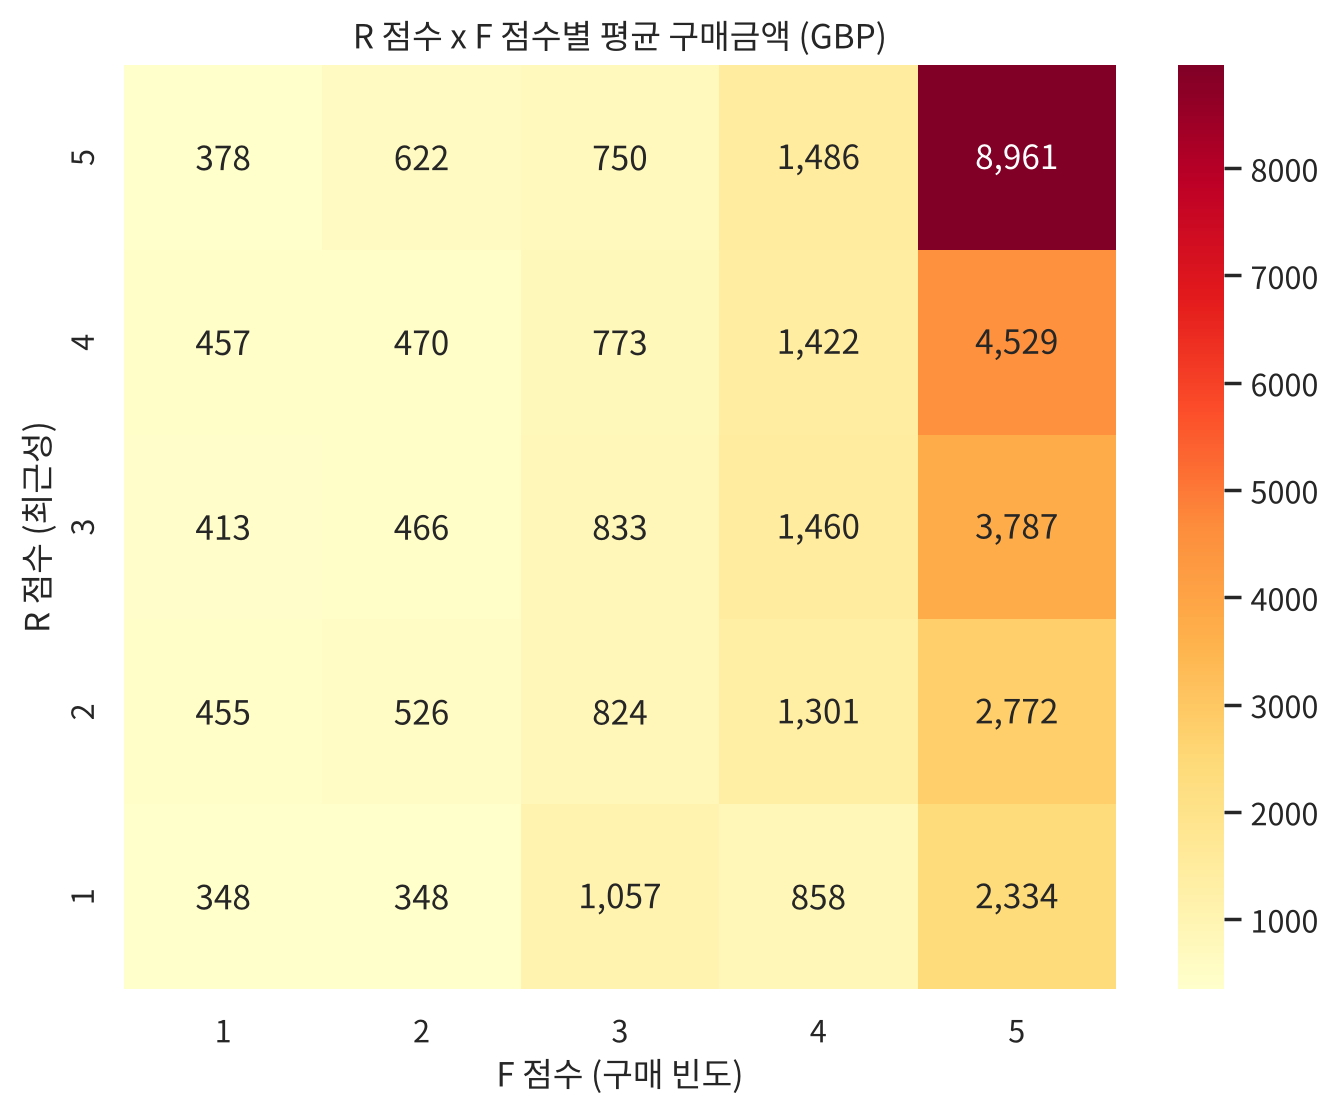

In [25]:
# R 점수 x F 점수 칸마다 평균 구매금액을 표시한다.
rf_table = rfm.pivot_table(index="R_score", columns="F_score",
                           values="Monetary", aggfunc="mean")
rf_table = rf_table.sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(rf_table, annot=True, fmt=",.0f", cmap="YlOrRd", ax=ax)
ax.set(title="R 점수 x F 점수별 평균 구매금액 (GBP)",
       xlabel="F 점수 (구매 빈도)", ylabel="R 점수 (최근성)")
save_figure(fig, "08_heatmap_rf_monetary.png")
plt.show()

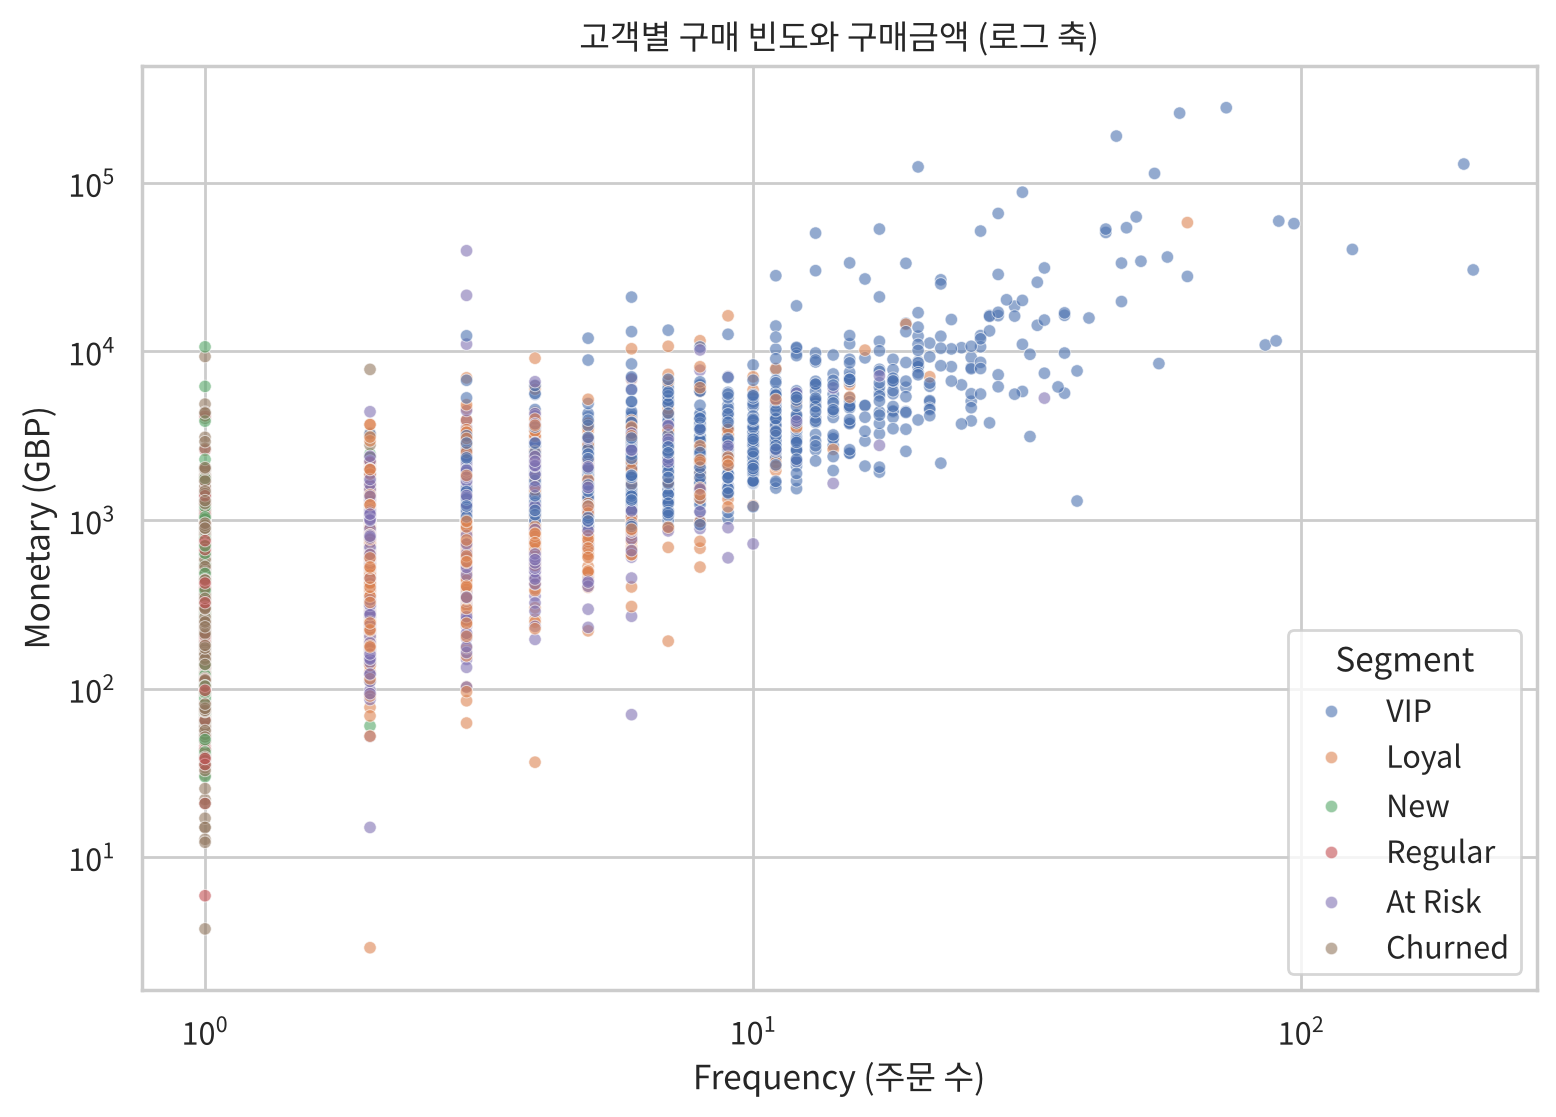

,Recency,Frequency,Monetary
Recency,1.00,-0.56,-0.48
Frequency,-0.56,1.00,0.81
Monetary,-0.48,0.81,1.00


In [26]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment",
                hue_order=SEGMENT_ORDER, alpha=0.6, s=20, ax=ax)
ax.set(xscale="log", yscale="log",
       title="고객별 구매 빈도와 구매금액 (로그 축)",
       xlabel="Frequency (주문 수)", ylabel="Monetary (GBP)")
save_figure(fig, "09_scatter_rfm_segments.png")
plt.show()

customer_corr = rfm[["Recency", "Frequency", "Monetary"]].corr(
    method="spearman")
customer_corr.round(3)

In [27]:
# 인사이트 근거용 수치
total_revenue = rfm["Monetary"].sum()
one_time = (rfm["Frequency"] == 1).mean() * 100
top_customers = rfm["Monetary"].sort_values(ascending=False)
top10_share = (top_customers.head(int(len(rfm) * 0.1)).sum()
               / total_revenue * 100)
at_risk = rfm[rfm["Segment"] == "At Risk"]
print(f"고객 수: {len(rfm):,}, 총 매출: {total_revenue:,.0f}")
print(f"1회 구매 고객 비율: {one_time:.1f}%")
print(f"상위 10% 고객의 매출 비중: {top10_share:.1f}%")
print(f"At Risk 평균 주문 수: {at_risk['Frequency'].mean():.2f}, "
      f"평균 미구매 기간: {at_risk['Recency'].mean():.1f}일, "
      f"매출 합계: {at_risk['Monetary'].sum():,.0f}")
print("New 고객 Recency 중앙값:",
      rfm.loc[rfm['Segment'] == 'New', 'Recency'].median())

고객 수: 4,321, 총 매출: 8,304,335
1회 구매 고객 비율: 34.6%
상위 10% 고객의 매출 비중: 60.1%
At Risk 평균 주문 수: 3.40, 평균 미구매 기간: 149.1일, 매출 합계: 776,089
New 고객 Recency 중앙값: 18.0


### 해석

**전체 분포**
- RFM 대상 고객은 4,321명이다(순구매액 1펜스 미만으로 제외된 14명 별도). 취소 금액 474,403파운드를 빼서 총 순구매액은 8,304,335파운드다.
- Recency 중앙값 50일, Frequency 중앙값 2회, Monetary 중앙값 654.60파운드다. Monetary 평균(1,921.85파운드)이 중앙값의 약 3배여서 소수 고객이 매출을 끌어올린다. 실제로 1회 구매 고객이 34.6%이고, 상위 10% 고객이 매출의 60.1%를 차지한다.
- 고객 단위 Spearman 상관은 Frequency-Monetary 0.81, Recency-Frequency -0.56이다. 자주 사는 고객이 많이 쓰고, 최근에 온 고객이 대체로 자주 오는 고객이다.

**세그먼트별 특징**

| 세그먼트 | 고객 수(비율) | 평균 Recency | 평균 Frequency | 평균 Monetary | 매출 비중 |
| --- | --- | --- | --- | --- | --- |
| VIP | 941 (21.78%) | 11.48일 | 11.12회 | 5,877.61 | 66.60% |
| Loyal | 995 (23.03%) | 32.32일 | 3.74회 | 1,270.39 | 15.22% |
| At Risk | 656 (15.18%) | 149.07일 | 3.40회 | 1,183.06 | 9.35% |
| Churned | 1,072 (24.81%) | 216.08일 | 1.10회 | 401.92 | 5.19% |
| Regular | 347 (8.03%) | 51.39일 | 1.15회 | 441.03 | 1.84% |
| New | 310 (7.17%) | 17.04일 | 1.25회 | 482.19 | 1.80% |

- **VIP**: 고객의 21.78%가 매출의 66.60%를 만든다. 한 명이 평균 11회 주문했다. 이 그룹의 이탈은 매출에 가장 치명적이다.
- **At Risk**: 평균 3.40회 주문한 경험 있는 고객인데 평균 149일 동안 사지 않았다. 매출 합계 776,089파운드로, 되돌릴 가치가 가장 큰 그룹이다.
- **Churned**: 가장 큰 그룹(24.81%)이지만 매출 비중은 5.19%다. 대부분 1회 구매 후 216일 넘게 오지 않았다.
- **New**: 310명이 최근(중앙값 18일 전) 1~2회 구매했다. 두 번째 구매로 이어지면 Loyal 후보가 된다.
- **히트맵**: R 점수 5 × F 점수 5 칸의 평균 구매금액이 8,961파운드로 가장 높고, F 점수가 같아도 R 점수가 낮아질수록 금액이 줄어든다(F=5에서 8,961 → 2,334). 구매 빈도가 금액과 가장 강하게 연결돼 있다.

**시사점**: 고객 수가 아니라 매출 비중으로 보면 VIP 유지와 At Risk 복귀가 우선순위다. Churned에 같은 예산을 쓰는 것은 효율이 낮다.

## 10. 결론과 한계

**결론**
1. 매출은 소수 고객에 집중돼 있다(상위 10% 고객이 60.1%, VIP 21.78%가 66.60%).
2. 매출은 9~11월에 몰린다(11월이 2월의 약 2.6배).
3. 경험 많은 이탈 위험 고객(At Risk)이 656명, 매출 776,089파운드 규모로 존재한다.

**한계**
- 고객 ID가 없는 24.93%의 거래는 RFM에서 빠졌다.
- 기간이 약 1년이라 계절성을 한 번만 관찰했다. 9~11월 증가가 매년 반복되는지는 다른 연도 데이터가 필요하다.
- 세그먼트 규칙(점수 경계)은 분석자가 정한 기준이다. 경계를 바꾸면 그룹 크기가 달라진다.
- 이미지는 무작위로 연결한 공개 데이터라 매출과의 관계를 해석할 수 없다.

비즈니스 인사이트와 실행 제안은 README.md에 정리했다.